In [8]:
import torch
from torch import nn
import matplotlib.pyplot as plt
import copy

Epoch 0: training loss = 1.4917550086975098
Epoch 1000: training loss = 0.015460164286196232
Epoch 2000: training loss = 0.015057973563671112
Epoch 3000: training loss = 0.014556920155882835
Epoch 4000: training loss = 0.01380317471921444
Epoch 5000: training loss = 0.012664198875427246
Epoch 6000: training loss = 0.011133787222206593
Epoch 7000: training loss = 0.009424920193850994
Epoch 8000: training loss = 0.007879785262048244
Epoch 9000: training loss = 0.006713527254760265
Final training loss: 0.005905617494136095
Test loss: 0.005631358828395605
Mean test endpoint error: 0.09020723402500153
Maximum test endpoint error: 0.27064111828804016


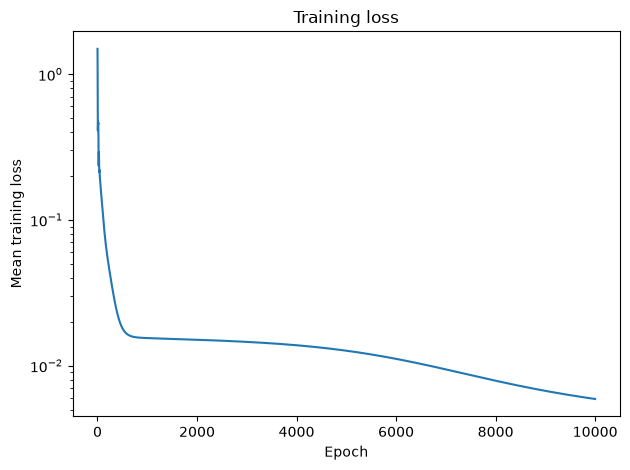

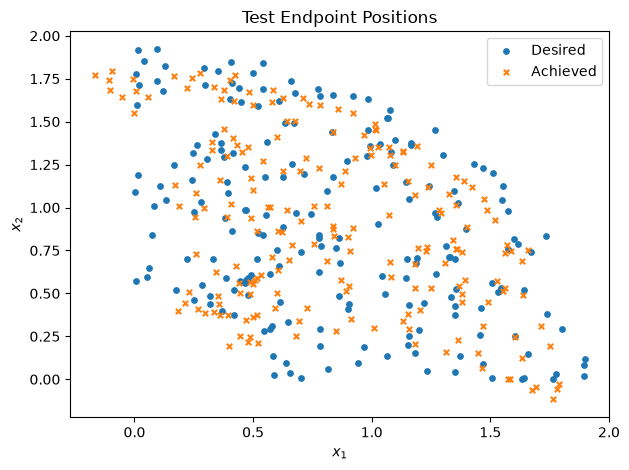

In [19]:
# part a
torch.manual_seed(0)

def kinematics(q):
    x1 = torch.cos(q[:, 0]) + torch.cos(q[:, 1])
    x2 = torch.sin(q[:, 0]) + torch.sin(q[:, 1])
    return torch.stack([x1, x2], dim=1)

direction = (torch.pi / 2) * torch.rand(1000)
bend = torch.pi / 6 + (2 * torch.pi / 3) * torch.rand(1000)
q1 = direction + bend / 2
q2 = direction - bend / 2

q_data = torch.stack([q1, q2], dim=1)
positions = kinematics(q_data)

x_train = positions[:800]
x_test = positions[800:]

model = nn.Sequential(nn.Linear(2, 16), nn.Sigmoid(), nn.Linear(16, 2))
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9) 
train_losses = []

for epoch in range(10000):
    q_predicted = model(x_train)
    x_predicted = kinematics(q_predicted)

    loss = 0.5 * (x_predicted - x_train).square().sum(dim=1).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: training loss = {loss.item()}")

with torch.no_grad():
    q_test = model(x_test)
    achieved = kinematics(q_test)
    errors = torch.linalg.vector_norm(achieved - x_test, dim=1)
    test_loss = 0.5 * errors.square().mean()

print(f"Final training loss: {train_losses[-1]}")
print(f"Test loss: {test_loss.item()}")
print(f"Mean test endpoint error: {errors.mean().item()}")
print(f"Maximum test endpoint error: {errors.max().item()}")

plt.figure()
plt.semilogy(train_losses)
plt.xlabel("Epoch")
plt.ylabel("Mean training loss")
plt.title("Training loss")
plt.tight_layout()

plt.figure()
plt.scatter(x_test[:, 0].tolist(), x_test[:, 1].tolist(), s=15, label="Desired")
plt.scatter(achieved[:, 0].tolist(), achieved[:, 1].tolist(), s=15, marker="x", label="Achieved")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Test Endpoint Positions")
plt.legend()
plt.tight_layout()

plt.show() 

Pretrained N/N-2 mean error: 0.04347873106598854

Case 1
Mean error through N/N-2 = 0.27357351779937744
Mean acutal endpoint error = 0.46040457487106323
Maximum acutal endoint error = 3.2377610206604004
N/N-2 forward error = 0.04347873106598854

Case 2
Mean error through N/N-2 = 0.0188688226044178
Mean acutal endpoint error = 1.2514033317565918
Maximum acutal endoint error = 2.214212656021118
N/N-2 forward error = 4.29389762878418


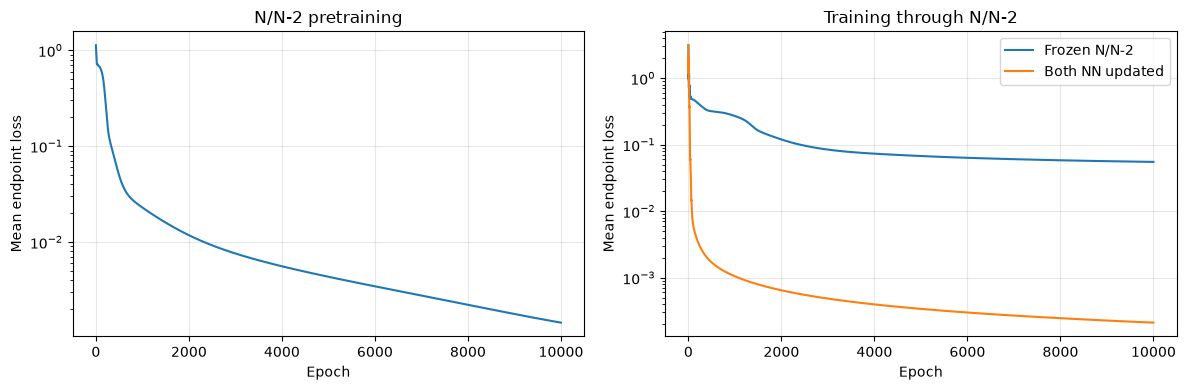

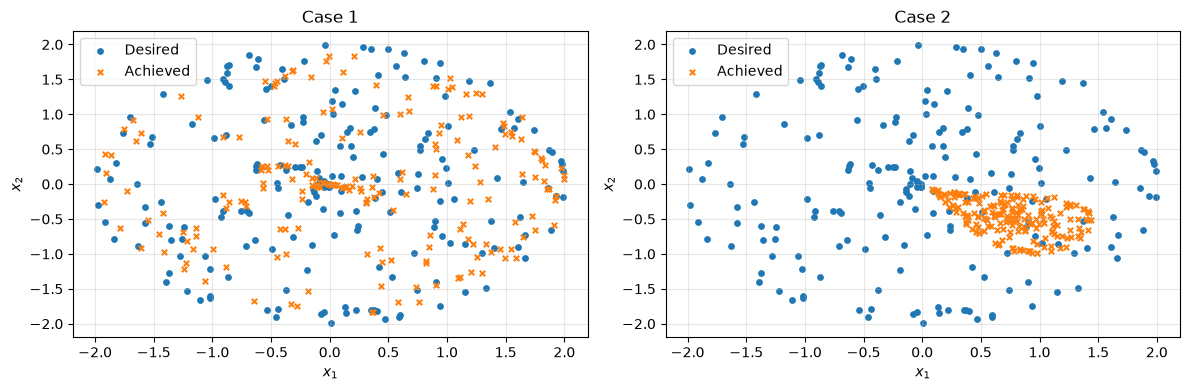

In [40]:
# part b

torch.manual_seed(0)

q_data = -torch.pi + 2 * torch.pi * torch.rand(1000, 2)
positions = kinematics(q_data)

q_train, q_test = q_data[:800], q_data[800:]
x_train, x_test = positions[:800], positions[800:]

# pretrain N/N-2
pretrained_forward = nn.Sequential(nn.Linear(2, 16), nn.Sigmoid(), nn.Linear(16, 2))
optimizer = torch.optim.SGD(pretrained_forward.parameters(), lr=0.03, momentum=0.9)

forward_losses = []

for epoch in range(10000):
    loss = 0.5 * (pretrained_forward(q_train) - x_train).square().sum(dim=1).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    forward_losses.append(loss.item())

with torch.no_grad():
    forward_error = torch.linalg.vector_norm(pretrained_forward(q_test) - x_test, dim=1)

print(f"Pretrained N/N-2 mean error: {forward_error.mean().item()}")

initial_inverse = nn.Sequential(nn.Linear(2, 16), nn.Sigmoid(), nn.Linear(16, 2))

# train N/N-1 through N/N-2
def train_case(update_forward):
    forward = copy.deepcopy(pretrained_forward)
    inverse = copy.deepcopy(initial_inverse)

    # case 1 - freeze N/N-2,    case 2 - allow N/N-2 to update
    forward.requires_grad_(update_forward)
    parameters = list(inverse.parameters())

    if update_forward:
        parameters += list(forward.parameters())

    optimizer = torch.optim.SGD(parameters, lr=0.03, momentum=0.9)
    losses = []

    for epoch in range(10000):
        predicted_angles = inverse(x_train)
        predicted_positions = forward(predicted_angles)
        loss = 0.5 * (predicted_positions - x_train).square().sum(dim=1).mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    return inverse, forward, losses

# case 1
inverse_1, forward_1, losses_1 = train_case(False)

#case 2
inverse_2, forward_2, losses_2 = train_case(True)

def evaluate(inverse, forward):
    with torch.no_grad():
        predicted_angles = inverse(x_test)
        model_positions = forward(predicted_angles)
        actual_positions = kinematics(predicted_angles)

        model_errors = torch.linalg.vector_norm(model_positions - x_test, dim=1) # both networks 
        actual_errors = torch.linalg.vector_norm(actual_positions - x_test, dim=1) # N/N-1
        forward_errors = torch.linalg.vector_norm(forward(q_test) - x_test, dim=1) # N/N-2

    print(f"Mean error through N/N-2 = {model_errors.mean().item()}")
    print(f"Mean acutal endpoint error = {actual_errors.mean().item()}")
    print(f"Maximum acutal endoint error = {actual_errors.max().item()}")
    print(f"N/N-2 forward error = {forward_errors.mean().item()}")

    return actual_positions

print("\nCase 1")
actual_1 = evaluate(inverse_1, forward_1)
print("\nCase 2")
actual_2 = evaluate(inverse_2, forward_2)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].semilogy(forward_losses)
axes[0].set_title("N/N-2 pretraining")

axes[1].semilogy(losses_1, label="Frozen N/N-2")
axes[1].semilogy(losses_2, label="Both NN updated")
axes[1].set_title("Training through N/N-2")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean endpoint loss")
    ax.grid(alpha=0.3)

fig.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for ax, actual, title in zip(axes, [actual_1, actual_2], ["Case 1", "Case 2"]):
    ax.scatter(x_test[:, 0].tolist(), x_test[:, 1].tolist(), s=15, label="Desired")
    ax.scatter(actual[:, 0].tolist(), actual[:, 1].tolist(), s=15, marker="x", label="Achieved")
    ax.set_title(title)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()
